In [1]:
import os
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import cv2

from PIL import Image, ImageFile
from tqdm.notebook import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
DATASET_ROOT = Path(
    r"E:\SEM5\ERA\ERA_Project\Brain_Tumor\data"
)

OUTPUT_DIR = Path(
    r"E:\SEM5\ERA\ERA_Project\Brain_Tumor\retraining_outputs\01_dataset_audit"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

IMG_SIZE = (224, 224)

print("Dataset exists:", DATASET_ROOT.exists())
print("Output directory:", OUTPUT_DIR)



Dataset exists: True
Output directory: E:\SEM5\ERA\ERA_Project\Brain_Tumor\retraining_outputs\01_dataset_audit


In [3]:
print("DATASET STRUCTURE")
print("=" * 60)

for item in DATASET_ROOT.iterdir():

    if item.is_dir():

        image_count = sum(
            1 for f in item.rglob("*")
            if f.is_file()
            and f.suffix.lower() in IMAGE_EXTENSIONS
        )

        print(f"[DIR] {item.name:25s} {image_count} images")

    elif item.is_file():

        print(f"[FILE] {item.name}")

        

DATASET STRUCTURE
[DIR] Testing                   1600 images
[DIR] Training                  5600 images


In [4]:
def detect_dataset_structure(root):

    directories = [
        p for p in root.iterdir()
        if p.is_dir()
    ]

    split_aliases = {
        "train": ["train", "training"],
        "test": ["test", "testing"],
        "val": ["val", "validation"]
    }

    split_dirs = {}

    for split, aliases in split_aliases.items():

        for directory in directories:

            if directory.name.lower() in aliases:

                split_dirs[split] = directory
                break

    if split_dirs:

        return split_dirs, "split"

    return {"all": root}, "class_only"


SPLIT_DIRS, DATASET_MODE = detect_dataset_structure(
    DATASET_ROOT
)

print("Dataset mode:", DATASET_MODE)

for split, path in SPLIT_DIRS.items():

    print(f"{split}: {path}")

    

Dataset mode: split
train: E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Training
test: E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testing


In [5]:
def calculate_hash(image_path):

    sha256 = hashlib.sha256()

    with open(image_path, "rb") as f:

        for chunk in iter(
            lambda: f.read(8192), b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


def extract_metadata(image_path):

    try:

        image = Image.open(image_path)
        image.load()

        width, height = image.size
        mode = image.mode

        image_rgb = image.convert("RGB")

        image_array = np.asarray(
            image_rgb,
            dtype=np.float32
        )

        gray = cv2.cvtColor(
            image_array.astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        )

        brightness = float(np.mean(gray))
        contrast = float(np.std(gray))

        # Rough estimate of non-black pixels.
        # This does NOT identify brain tissue.
        foreground_ratio = float(
            np.mean(gray > 10)
        )

        return {

            "width": width,
            "height": height,

            "aspect_ratio": width / height,

            "mode": mode,

            "file_size_kb": (
                os.path.getsize(image_path) / 1024
            ),

            "brightness_mean": brightness,

            "brightness_std": contrast,

            "min_intensity": int(np.min(gray)),

            "max_intensity": int(np.max(gray)),

            "foreground_ratio": foreground_ratio,

            "red_mean": float(
                np.mean(image_array[:, :, 0])
            ),

            "green_mean": float(
                np.mean(image_array[:, :, 1])
            ),

            "blue_mean": float(
                np.mean(image_array[:, :, 2])
            ),

            "image_hash": calculate_hash(image_path),

            "valid": True

        }

    except Exception as e:

        return {
            "valid": False,
            "error": str(e)
        }

        

In [6]:
records = []

for split, split_path in SPLIT_DIRS.items():

    print(f"\nProcessing {split.upper()}")

    class_directories = [
        p for p in split_path.iterdir()
        if p.is_dir()
    ]

    for class_dir in sorted(class_directories):

        image_files = [
            f for f in class_dir.rglob("*")
            if f.is_file()
            and f.suffix.lower() in IMAGE_EXTENSIONS
        ]

        print(
            f"Processing {class_dir.name}: "
            f"{len(image_files)} images"
        )

        for image_path in tqdm(image_files):

            metadata = extract_metadata(image_path)

            record = {

                "split": split,

                "class": class_dir.name,

                "filename": image_path.name,

                "path": str(image_path)

            }

            record.update(metadata)

            records.append(record)


df = pd.DataFrame(records)

print("\nMetadata extraction completed.")

print("Total images:", len(df))

print("Valid images:", df["valid"].sum())

print(
    "Invalid images:",
    (~df["valid"]).sum()
)

df.head()




Processing TRAIN
Processing glioma: 1400 images


  0%|          | 0/1400 [00:00<?, ?it/s]

Processing meningioma: 1400 images


  0%|          | 0/1400 [00:00<?, ?it/s]

Processing notumor: 1400 images


  0%|          | 0/1400 [00:00<?, ?it/s]

... (8 outputs left out)

Processing pituitary: 400 images


  0%|          | 0/400 [00:00<?, ?it/s]


Metadata extraction completed.
Total images: 7200
Valid images: 7200
Invalid images: 0


,split,class,filename,path,width,height,aspect_ratio,mode,file_size_kb,brightness_mean,brightness_std,min_intensity,max_intensity,foreground_ratio,red_mean,green_mean,blue_mean,image_hash,valid
0,train,glioma,Tr-gl_1.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,512,512,1.0,L,20.402344,34.543823,36.679668,0,255,0.566460,34.543823,34.543823,34.543823,5ac3fbd85891bf49b4c337ea49d7f382698f960c046a3d...,True
1,train,glioma,Tr-gl_10.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,512,512,1.0,L,25.835938,48.690544,44.468923,0,255,0.664124,48.690544,48.690544,48.690544,1941099deff1ed62185051bc1eb912abc87af9ff403390...,True
2,train,glioma,Tr-gl_100.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,512,512,1.0,L,19.677734,43.763042,46.088195,0,255,0.526791,43.763042,43.763042,43.763042,544aa9e1829e61d95d5c2b68863dd2bd98bb44eaa19822...,True
3,train,glioma,Tr-gl_1000.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,512,512,1.0,L,24.308594,41.368168,39.930308,0,255,0.639290,41.368168,41.368168,41.368168,88b2a7e2adcc2f9b23ef908bb3063f2585068b350ab86a...,True
4,train,glioma,Tr-gl_1001.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,512,512,1.0,L,14.410156,27.382278,39.787180,0,255,0.357292,27.382278,27.382278,27.382278,48a0ad607d04b380ae7c8a40558677f63351ea6696b706...,True


In [7]:
class_distribution = (
    df[df["valid"]]
    .groupby(["split", "class"])
    .size()
    .unstack(fill_value=0)
)

display(class_distribution)

class_distribution.to_csv(
    OUTPUT_DIR / "class_distribution.csv"
)



class,glioma,meningioma,notumor,pituitary
split,,,,
test,400,400,400,400
train,1400,1400,1400,1400


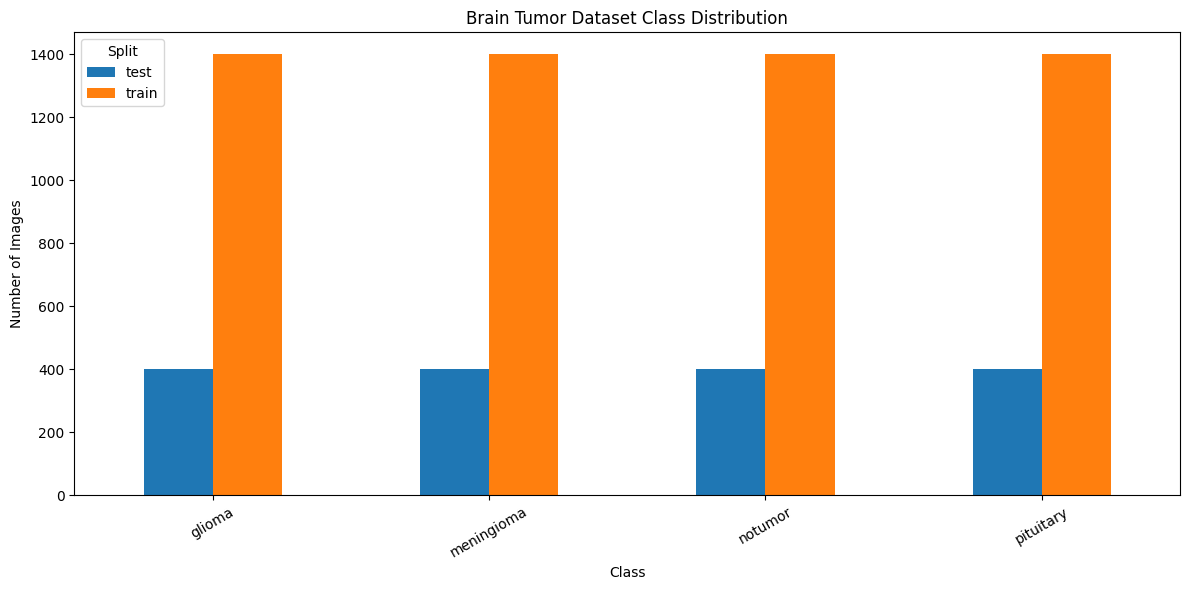

In [8]:
class_distribution.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Brain Tumor Dataset Class Distribution")

plt.xlabel("Class")

plt.ylabel("Number of Images")

plt.xticks(rotation=30)

plt.legend(title="Split")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "class_distribution.png",
    dpi=300
)

plt.show()



In [9]:
valid_df = df[df["valid"]].copy()

print("IMAGE DIMENSION STATISTICS")

display(
    valid_df[
        ["width", "height", "aspect_ratio"]
    ].describe()
)



IMAGE DIMENSION STATISTICS


,width,height,aspect_ratio
count,7200.000000,7200.000000,7200.000000
mean,453.302917,456.899167,0.989699
std,130.048964,124.402496,0.091677
min,150.000000,167.000000,0.644809
25%,442.000000,449.000000,1.000000
50%,512.000000,512.000000,1.000000
75%,512.000000,512.000000,1.000000
max,1375.000000,1446.000000,1.785714


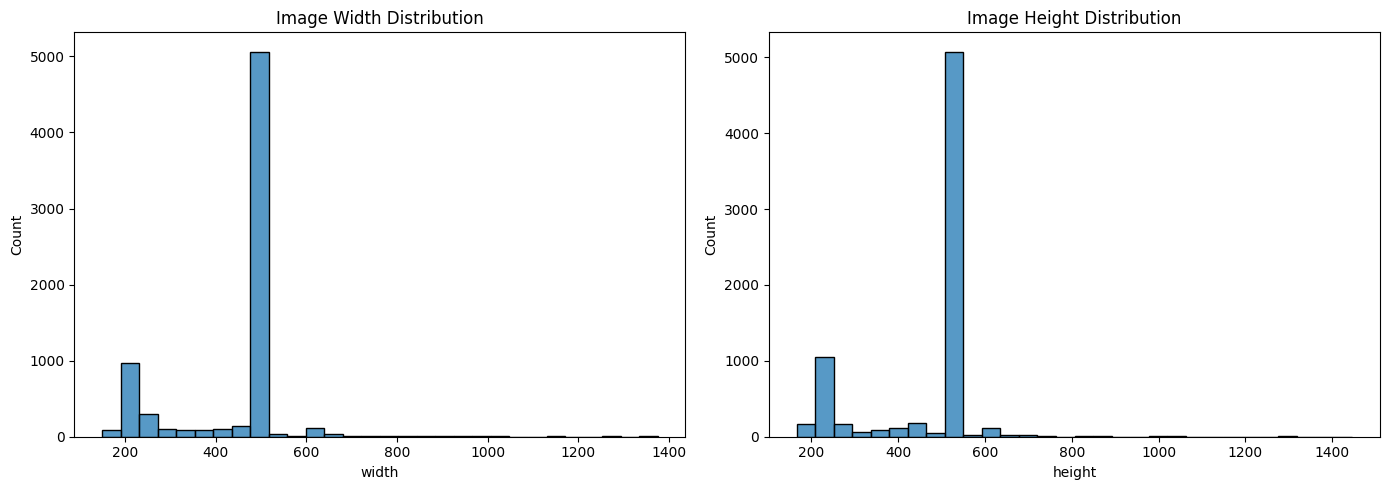

In [10]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

sns.histplot(
    valid_df["width"],
    bins=30,
    ax=axes[0]
)

axes[0].set_title("Image Width Distribution")

sns.histplot(
    valid_df["height"],
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Image Height Distribution")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "image_dimensions.png",
    dpi=300
)

plt.show()



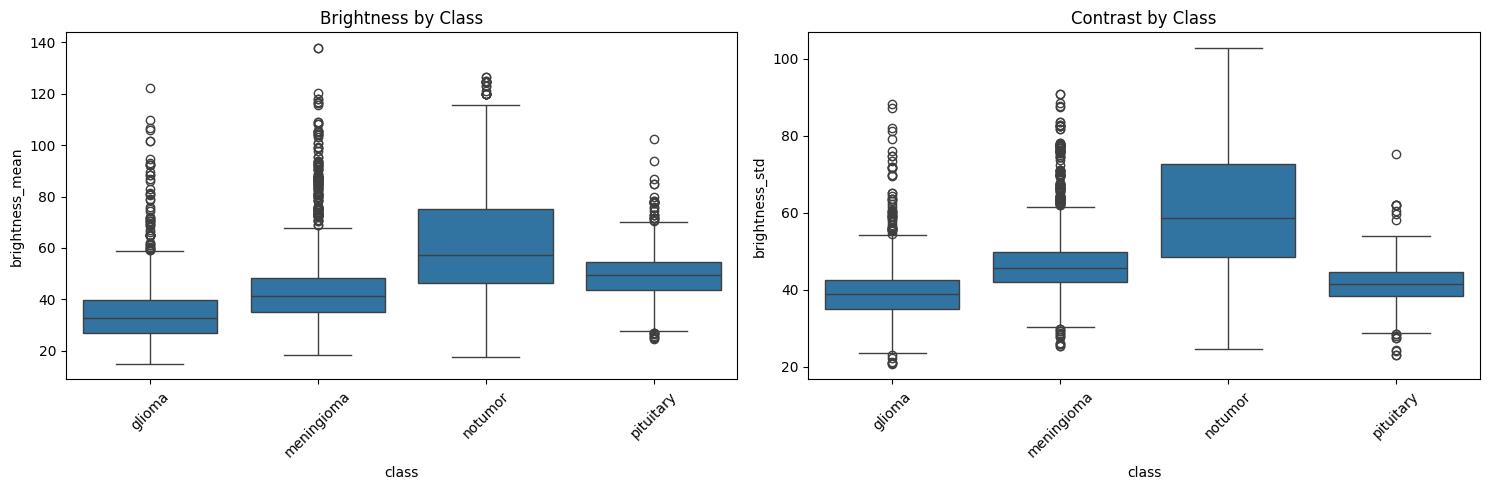

In [11]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

sns.boxplot(
    data=valid_df,
    x="class",
    y="brightness_mean",
    ax=axes[0]
)

axes[0].set_title("Brightness by Class")

axes[0].tick_params(
    axis="x",
    rotation=45
)

sns.boxplot(
    data=valid_df,
    x="class",
    y="brightness_std",
    ax=axes[1]
)

axes[1].set_title("Contrast by Class")

axes[1].tick_params(
    axis="x",
    rotation=45
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "brightness_contrast.png",
    dpi=300
)

plt.show()


In [12]:
duplicate_counts = (
    valid_df.groupby("image_hash")
    .size()
    .reset_index(name="count")
)

duplicates = duplicate_counts[
    duplicate_counts["count"] > 1
]

print("Unique duplicated image hashes:", len(duplicates))

print(
    "Total images belonging to duplicate groups:",
    duplicates["count"].sum()
)

Unique duplicated image hashes: 153
Total images belonging to duplicate groups: 340


In [14]:
duplicate_details = valid_df.merge(
    duplicates,
    on="image_hash",
    how="inner"
)

display(
    duplicate_details.sort_values("image_hash")[
        ["split", "class", "filename", "path", "count"]
    ]
)

duplicate_details.to_csv(
    OUTPUT_DIR / "duplicate_images.csv",
    index=False
)

,split,class,filename,path,count
333,test,glioma,Te-gl_389.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,2
329,test,glioma,Te-gl_32.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,2
33,train,notumor,Tr-no_1046.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,2
152,train,notumor,Tr-no_454.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,2
18,train,meningioma,Tr-me_532.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,2
...,...,...,...,...,...
55,train,notumor,Tr-no_1158.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,3
129,train,notumor,Tr-no_330.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,3
35,train,notumor,Tr-no_1051.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,3
62,train,notumor,Tr-no_1190.jpg,E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,2


In [15]:
if {"train", "test"}.issubset(
    set(valid_df["split"].unique())
):

    train_hashes = set(
        valid_df[
            valid_df["split"] == "train"
        ]["image_hash"]
    )

    test_hashes = set(
        valid_df[
            valid_df["split"] == "test"
        ]["image_hash"]
    )

    cross_split_hashes = train_hashes & test_hashes

    print(
        "Exact duplicates across train/test:",
        len(cross_split_hashes)
    )

    cross_split_duplicates = valid_df[
        valid_df["image_hash"].isin(
            cross_split_hashes
        )
    ]

    display(
        cross_split_duplicates[
            ["split", "class", "filename", "path"]
        ]
    )

else:

    print(
        "Separate train/test folders were not detected."
    )

    

Exact duplicates across train/test: 0


,split,class,filename,path


In [16]:
label_conflicts = (
    valid_df.groupby("image_hash")["class"]
    .nunique()
)

conflict_hashes = label_conflicts[
    label_conflicts > 1
].index

conflict_df = valid_df[
    valid_df["image_hash"].isin(conflict_hashes)
]

print(
    "Images with conflicting labels:",
    len(conflict_hashes)
)

display(
    conflict_df[
        ["split", "class", "filename", "path"]
    ]
)



Images with conflicting labels: 0


,split,class,filename,path


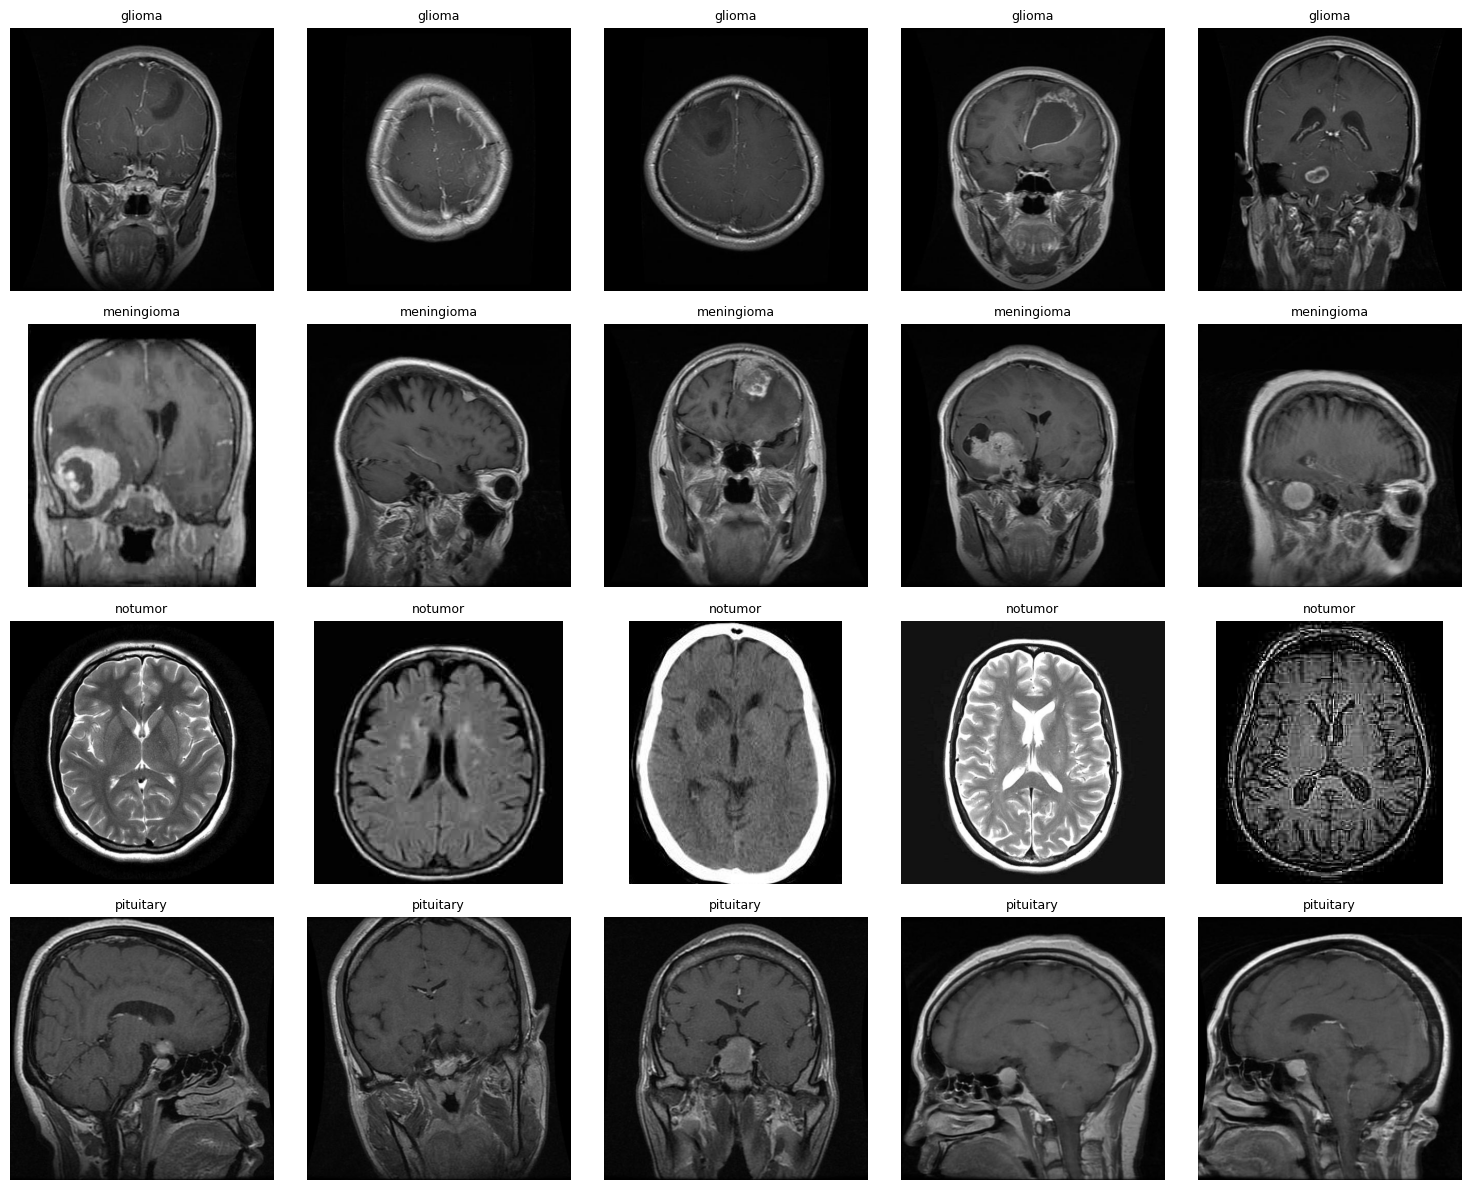

In [17]:
def display_random_images(
    dataframe,
    images_per_class=5
):

    classes = sorted(
        dataframe["class"].unique()
    )

    fig, axes = plt.subplots(
        len(classes),
        images_per_class,
        figsize=(15, 3 * len(classes))
    )

    for row, class_name in enumerate(classes):

        class_df = dataframe[
            dataframe["class"] == class_name
        ]

        samples = class_df.sample(
            min(images_per_class, len(class_df)),
            random_state=SEED
        )

        for col in range(images_per_class):

            ax = axes[row, col]

            ax.axis("off")

            if col >= len(samples):
                continue

            image_path = samples.iloc[col]["path"]

            image = Image.open(
                image_path
            ).convert("RGB")

            ax.imshow(image)

            ax.set_title(
                class_name,
                fontsize=9
            )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "random_mri_samples.png",
        dpi=250
    )

    plt.show()


display_random_images(
    valid_df,
    images_per_class=5
)



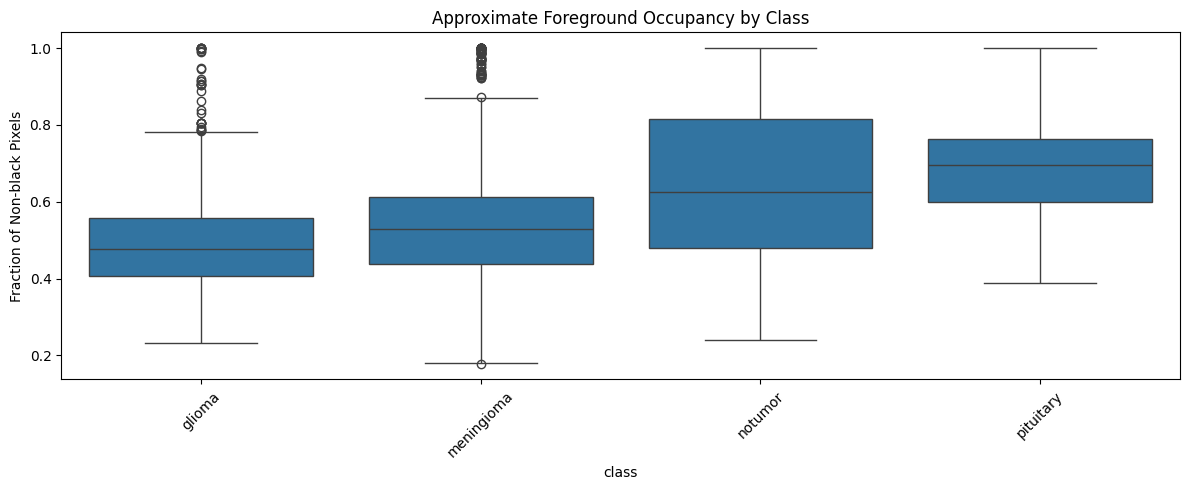

In [18]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=valid_df,
    x="class",
    y="foreground_ratio"
)

plt.title("Approximate Foreground Occupancy by Class")

plt.xticks(rotation=45)

plt.ylabel("Fraction of Non-black Pixels")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "foreground_occupancy.png",
    dpi=300
)

plt.show()



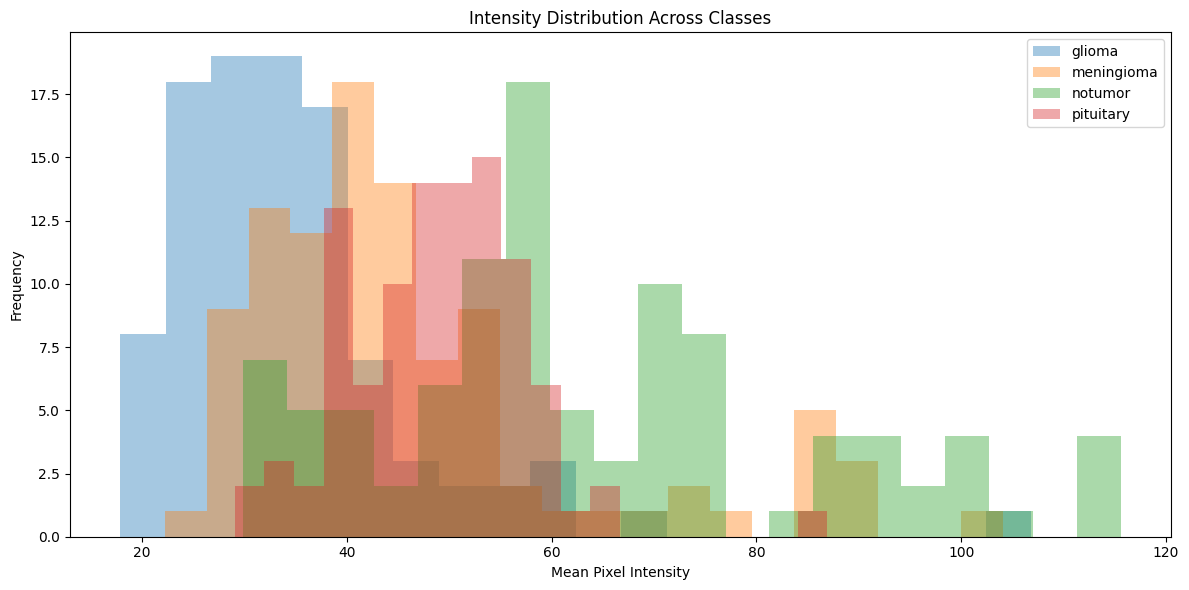

In [19]:
def plot_intensity_distribution(dataframe):

    classes = sorted(
        dataframe["class"].unique()
    )

    plt.figure(figsize=(12, 6))

    for class_name in classes:

        sample = dataframe[
            dataframe["class"] == class_name
        ].sample(
            min(100, len(dataframe[
                dataframe["class"] == class_name
            ])),
            random_state=SEED
        )

        plt.hist(
            sample["brightness_mean"],
            bins=20,
            alpha=0.4,
            label=class_name
        )

    plt.xlabel("Mean Pixel Intensity")

    plt.ylabel("Frequency")

    plt.title("Intensity Distribution Across Classes")

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "intensity_distribution.png",
        dpi=300
    )

    plt.show()


plot_intensity_distribution(valid_df)



In [20]:
report = {

    "total_images": int(len(df)),

    "valid_images": int(df["valid"].sum()),

    "invalid_images": int((~df["valid"]).sum()),

    "number_of_classes": int(
        valid_df["class"].nunique()
    ),

    "classes": sorted(
        valid_df["class"].unique().tolist()
    ),

    "duplicate_hash_groups": int(
        len(duplicates)
    ),

    "conflicting_label_groups": int(
        len(conflict_hashes)
    ),

    "mean_width": float(
        valid_df["width"].mean()
    ),

    "mean_height": float(
        valid_df["height"].mean()
    ),

    "mean_brightness": float(
        valid_df["brightness_mean"].mean()
    ),

    "mean_contrast": float(
        valid_df["brightness_std"].mean()
    ),

    "mean_foreground_ratio": float(
        valid_df["foreground_ratio"].mean()
    )

}

import json

with open(
    OUTPUT_DIR / "audit_report.json",
    "w"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

valid_df.to_csv(
    OUTPUT_DIR / "image_metadata.csv",
    index=False
)

print("=" * 60)

print("DATASET AUDIT COMPLETED")

print("=" * 60)

for key, value in report.items():

    print(f"{key}: {value}")

print("\nResults saved at:")

print(OUTPUT_DIR)



DATASET AUDIT COMPLETED
total_images: 7200
valid_images: 7200
invalid_images: 0
number_of_classes: 4
classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
duplicate_hash_groups: 153
conflicting_label_groups: 0
mean_width: 453.30291666666665
mean_height: 456.89916666666664
mean_brightness: 47.55819109961717
mean_contrast: 47.158952967252304
mean_foreground_ratio: 0.591456256078648

Results saved at:
E:\SEM5\ERA\ERA_Project\Brain_Tumor\retraining_outputs\01_dataset_audit
